# SVC Clustering Classification: C vs IP and IM vs IP

This notebook trains a classical Support Vector Classifier on the data-driven clustering results exported by `10_clustering.ipynb`. It mirrors the EEGNet clustering setup from notebooks `11` and `17`: selected cluster channels, band-specific filtering, dynamic cluster time windows, development-only grouped CV, versioned OOF caches, and a final chronological holdout evaluated once.


## 1. Environment and Imports

In [6]:
import os
import sys
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.signal import hilbert
from scipy.special import expit
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

try:
    NOTEBOOK_DIR = Path(__file__).resolve().parent
except NameError:
    NOTEBOOK_DIR = Path.cwd()

IS_KAGGLE = False
IN_COLAB = (not IS_KAGGLE) and ("google.colab" in sys.modules or "COLAB_GPU" in os.environ)
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")


def find_source_dir():
    candidates = []
    if IN_COLAB:
        candidates.append(Path("/content/drive/MyDrive/TFG_Nils_2026/03_Codi"))
    elif IS_KAGGLE:
        candidates.extend([Path("/kaggle/working"), Path("/kaggle/input")])
    candidates.extend([NOTEBOOK_DIR, NOTEBOOK_DIR.parent, NOTEBOOK_DIR.parent.parent / "src"])
    for candidate in candidates:
        if (candidate / "br_analysis" / "__init__.py").exists():
            return candidate
        if candidate.exists():
            for nested in candidate.glob("**/br_analysis/__init__.py"):
                return nested.parent.parent
    raise FileNotFoundError("Could not locate br_analysis. Add the project src folder to sys.path.")

SRC_DIR = find_source_dir()
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from br_analysis import (
    BinaryTaskConfig,
    COMMON_BAND_RANGES,
    FusedBandSpec,
    TARGET_BANDS_CLUSTERS,
    detect_project_paths,
    get_task_config,
    load_fused_band_dataset,
)
from br_analysis.experiments import chronological_group_labels, stratified_group_splits

mne.set_log_level("WARNING")
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=UserWarning)

RANDOM_SEED = 42
HOLDOUT_FRAC = 0.20
N_SPLITS = 5
OOF_CACHE_VERSION = "stratified_group_kfold_holdout_v1"
OOF_CV_STRATEGY = "stratified_group_kfold_development_only"
TASKS = ["c_vs_ip", "im_vs_ip"]

paths = detect_project_paths("svc_clustering", in_colab=IN_COLAB, in_kaggle=IS_KAGGLE)
comparison_paths = detect_project_paths("cross_model_comparison", in_colab=IN_COLAB, in_kaggle=IS_KAGGLE)

print("Working Paths:")
print("  Analysis:", paths.analysis_dir)
print("  Cache:", paths.cache_dir)
print("  Tables:", paths.tables_dir)
print("  Figures:", paths.figures_dir)
print("  Comparison cache:", comparison_paths.cache_dir)

Working Paths:
  Analysis: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\svc_clustering
  Cache: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\svc_clustering\cache
  Tables: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\svc_clustering\tables
  Figures: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\svc_clustering\figures
  Comparison cache: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\cross_model_comparison\cache


## 2. Load Data-Driven Cluster Definitions

In [7]:
cluster_def_path = paths.analysis_root / "clustering" / "cluster_definitions.json"
if cluster_def_path.exists():
    with open(cluster_def_path, "r", encoding="utf-8") as f:
        cluster_defs = json.load(f)
    print(f"Loaded cluster definitions from: {cluster_def_path}")
else:
    cluster_defs = {}
    print("Cluster definitions not found. Falling back to TARGET_BANDS_CLUSTERS and full 0.0-1.5 s window.")

print(json.dumps(cluster_defs, indent=2))

Loaded cluster definitions from: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\clustering\cluster_definitions.json
{
  "c_vs_ip": {
    "theta": {
      "channels": [
        "Fz",
        "FCz"
      ],
      "tmin": 1.171875,
      "tmax": 1.2421875
    },
    "alpha": {
      "channels": [
        "FC3",
        "FC1",
        "FC2",
        "C3",
        "C1",
        "Cz",
        "C2",
        "CP3",
        "CP1",
        "CPz",
        "CP2",
        "CP4",
        "P5",
        "P3",
        "P1",
        "Pz",
        "P2",
        "P4",
        "P6",
        "P8",
        "PO3",
        "POz",
        "PO4",
        "PO8",
        "O1",
        "Oz",
        "O2"
      ],
      "tmin": 0.375,
      "tmax": 1.2421875
    }
  },
  "im_vs_ip": {
    "theta": {
      "channels": [
        "Fz",
        "FCz",
        "Cz"
      ],
      "tmin": 1.1953125,
      "tmax": 1.2421875
    },
    "alpha": {
      "channels": [
        "TP7",
    

## 3. Feature Extraction and Model Helpers

In [8]:
def task_label(task_name):
    return "C vs IP" if task_name == "c_vs_ip" else "IM vs IP"


def subject_development_holdout_indices(n_samples, holdout_frac=HOLDOUT_FRAC):
    cutoff = int(np.floor((1.0 - holdout_frac) * n_samples))
    cutoff = max(1, min(cutoff, n_samples - 1))
    return np.arange(cutoff), np.arange(cutoff, n_samples)


def cluster_settings_for_task(task_name):
    task_clusters = cluster_defs.get(task_name, {})
    active_bands = {
        band: info
        for band, info in task_clusters.items()
        if info.get("channels") and info.get("tmin") is not None and info.get("tmax") is not None
    }
    if active_bands:
        target_bands = {band: info["channels"] for band, info in active_bands.items()}
        tmin_crop = min(float(info["tmin"]) for info in active_bands.values())
        tmax_crop = max(float(info["tmax"]) for info in active_bands.values())
        print(f"{task_name}: using data-driven bands {list(active_bands)} from {tmin_crop:.3f}s to {tmax_crop:.3f}s")
        return target_bands, active_bands, (tmin_crop, tmax_crop)

    print(f"{task_name}: no exported clusters found; using heuristic TARGET_BANDS_CLUSTERS over 0.0-1.5s")
    fallback = {
        band: {"channels": channels, "tmin": 0.0, "tmax": 1.5}
        for band, channels in TARGET_BANDS_CLUSTERS.items()
    }
    return TARGET_BANDS_CLUSTERS, fallback, (0.0, 1.5)


def crop_task_config(task, window):
    return BinaryTaskConfig(
        name=task.name,
        class_0=task.class_0,
        class_1=task.class_1,
        event_codes=task.event_codes,
        selected_subjects_csv=task.selected_subjects_csv,
        max_subjects=task.max_subjects,
        undersample_classes=task.undersample_classes,
        analysis_window=window,
        random_seed=task.random_seed,
    )


def extract_cluster_svc_features(dataset, band_cluster_info):
    # Return compact per-trial SVC features tied to the exported cluster windows.
    feature_blocks = []
    feature_names = []
    times = np.asarray(dataset.times)

    for band in ["theta", "alpha"]:
        if band not in dataset.X or band not in band_cluster_info:
            continue
        X_band = np.asarray(dataset.X[band], dtype=np.float32)
        info = band_cluster_info[band]
        tmin, tmax = float(info.get("tmin", times[0])), float(info.get("tmax", times[-1]))
        t_mask = (times >= tmin) & (times <= tmax)
        if not np.any(t_mask):
            nearest = int(np.argmin(np.abs(times - 0.5 * (tmin + tmax))))
            t_mask = np.zeros_like(times, dtype=bool)
            t_mask[nearest] = True

        X_win = X_band[:, :, t_mask]
        env = np.abs(hilbert(X_win, axis=-1))
        mean_env = env.mean(axis=-1)
        log_power = np.log(np.maximum(np.square(X_win).mean(axis=-1), 1e-20))
        temporal_std = X_win.std(axis=-1)
        block = np.concatenate([mean_env, log_power, temporal_std], axis=1).astype(np.float32)
        feature_blocks.append(block)

        ch_names = dataset.channel_names.get(band, [])
        for stat in ["mean_env", "log_power", "std"]:
            feature_names.extend([f"{band}_{ch}_{stat}" for ch in ch_names])

        print(
            f"  {band}: {X_band.shape[1]} channels, window {tmin:.3f}-{tmax:.3f}s, "
            f"features {block.shape[1]}"
        )

    if not feature_blocks:
        raise RuntimeError("No feature blocks were created. Check cluster definitions and dataset bands.")
    return np.concatenate(feature_blocks, axis=1), feature_names


def make_svc_model():
    return make_pipeline(
        StandardScaler(),
        SVC(
            C=1.0,
            kernel="rbf",
            gamma="scale",
            class_weight="balanced",
            probability=False,
            random_state=RANDOM_SEED,
        ),
    )


def svc_decision_probability(clf, X):
    svc = clf.named_steps["svc"]
    decision = clf.decision_function(X)
    if list(svc.classes_) != [0, 1]:
        raise ValueError(f"Unexpected SVC classes: {svc.classes_}; expected [0, 1].")
    return expit(decision).astype(np.float32)


def metric_row(task_name, subject, split_name, y_true, y_pred, y_score):
    try:
        auc_value = roc_auc_score(y_true, y_score)
    except ValueError:
        auc_value = np.nan
    acc = accuracy_score(y_true, y_pred)
    bal_acc = balanced_accuracy_score(y_true, y_pred)
    fold = int(split_name.rsplit("_", 1)[-1]) if split_name.startswith("dev_fold_") else np.nan
    return {
        "Task": task_name,
        "Subject": subject,
        "subject": subject,
        "Model": "SVC_Clustering",
        "model": "SVC_Clustering",
        "Split": split_name,
        "fold": fold,
        "Accuracy": acc,
        "Balanced Accuracy": bal_acc,
        "test_acc": acc,
        "test_balanced_acc": bal_acc,
        "ROC AUC": auc_value,
        "test_auc": auc_value,
        "N Test": len(y_true),
    }

## 4. Run SVC Clustering for Both Contrasts

In [9]:
all_dev_rows = []
all_final_rows = []

task_outputs = {}

for task_name in TASKS:
    print("\n" + "=" * 72)
    print(f"Running SVC clustering model: {task_label(task_name)}")
    print("=" * 72)

    task = get_task_config(task_name, paths.analysis_root)
    target_bands, active_band_info, analysis_window = cluster_settings_for_task(task_name)
    task_cropped = crop_task_config(task, analysis_window)

    spec = FusedBandSpec(
        target_bands_clusters=target_bands,
        band_ranges=COMMON_BAND_RANGES,
        channel_mode=("fused",),
    )
    dataset = load_fused_band_dataset(paths, task_cropped, spec)
    X_feat, feature_names = extract_cluster_svc_features(dataset, active_band_info)
    y = np.asarray(dataset.y, dtype=np.int64)
    subjects = np.asarray(dataset.subjects, dtype=object)
    subject_ids = pd.unique(subjects).tolist()

    print(f"Feature matrix: {X_feat.shape[0]} trials x {X_feat.shape[1]} features")
    print(f"Subjects: {len(subject_ids)}")

    dev_rows = []
    final_rows = []
    oof_by_subject = {}
    final_true, final_pred, final_score = [], [], []

    for sub in subject_ids:
        mask = subjects == sub
        X_sub = X_feat[mask]
        y_sub = y[mask]

        splits = stratified_group_splits(
            y_sub,
            groups=chronological_group_labels(len(y_sub)),
            n_splits=N_SPLITS,
            holdout_frac=HOLDOUT_FRAC,
        )

        sub_true, sub_pred, sub_prob = [], [], []
        for fold, (train_idx, val_idx) in enumerate(splits, start=1):
            clf = make_svc_model()
            clf.fit(X_sub[train_idx], y_sub[train_idx])
            prob = svc_decision_probability(clf, X_sub[val_idx])
            pred = clf.predict(X_sub[val_idx])
            dev_rows.append(metric_row(task_name, sub, f"dev_fold_{fold}", y_sub[val_idx], pred, prob))
            sub_true.extend(y_sub[val_idx])
            sub_pred.extend(pred)
            sub_prob.extend(prob)

        if sub_true:
            oof_by_subject[sub] = {
                "y_true": np.asarray(sub_true, dtype=np.int64),
                "y_pred": np.asarray(sub_pred, dtype=np.int64),
                "prob": np.asarray(sub_prob, dtype=np.float32),
            }

        dev_idx, hold_idx = subject_development_holdout_indices(len(y_sub), HOLDOUT_FRAC)
        if len(np.unique(y_sub[dev_idx])) < 2 or len(np.unique(y_sub[hold_idx])) < 2:
            print(f"  Skipping final holdout for {sub}: holdout lacks both classes")
            continue

        clf = make_svc_model()
        clf.fit(X_sub[dev_idx], y_sub[dev_idx])
        prob = svc_decision_probability(clf, X_sub[hold_idx])
        pred = clf.predict(X_sub[hold_idx])
        final_rows.append(metric_row(task_name, sub, "final_holdout", y_sub[hold_idx], pred, prob))
        final_true.extend(y_sub[hold_idx])
        final_pred.extend(pred)
        final_score.extend(prob)

    df_dev = pd.DataFrame(dev_rows)
    df_final = pd.DataFrame(final_rows)
    all_dev_rows.extend(dev_rows)
    all_final_rows.extend(final_rows)

    task_stub = task_name
    dev_path = paths.tables_dir / f"svc_clustering_{task_stub}_development_cv.csv"
    final_path = paths.tables_dir / f"svc_clustering_{task_stub}_final_holdout_ONCE.csv"
    feature_path = paths.tables_dir / f"svc_clustering_{task_stub}_features.csv"

    df_dev.to_csv(dev_path, index=False)
    df_final.to_csv(final_path, index=False)
    pd.DataFrame({"feature": feature_names}).to_csv(feature_path, index=False)

    oof_payload = {}
    for sub, pred_data in oof_by_subject.items():
        oof_payload[f"{sub}_y_true"] = pred_data["y_true"]
        oof_payload[f"{sub}_y_pred"] = pred_data["y_pred"]
        oof_payload[f"{sub}_prob"] = pred_data["prob"]
    oof_payload["_cache_version"] = np.array(OOF_CACHE_VERSION)
    oof_payload["_cv_strategy"] = np.array(OOF_CV_STRATEGY)
    oof_payload["_holdout_frac"] = np.array(HOLDOUT_FRAC)
    oof_payload["_feature_kind"] = np.array("cluster_band_window_envelope_power_std")
    oof_payload["_score_kind"] = np.array("svc_decision_function_sigmoid")

    local_oof_path = paths.cache_dir / f"oof_predictions_{task_stub}_svc_clustering.npz"
    comparison_oof_path = comparison_paths.cache_dir / f"oof_predictions_{task_stub}_svc_clustering.npz"
    np.savez_compressed(local_oof_path, **oof_payload)
    np.savez_compressed(comparison_oof_path, **oof_payload)

    print("Development CV saved to:", dev_path)
    print("Final holdout saved to:", final_path)
    print("OOF predictions saved to:", local_oof_path)
    print("Comparison OOF cache saved to:", comparison_oof_path)

    if not df_dev.empty:
        print("\nDevelopment CV by subject:")
        print(df_dev.groupby("Subject")[["Accuracy", "Balanced Accuracy", "ROC AUC"]].mean().describe().to_string())
        oof_true = np.concatenate([v["y_true"] for v in oof_by_subject.values()]) if oof_by_subject else []
        oof_pred = np.concatenate([v["y_pred"] for v in oof_by_subject.values()]) if oof_by_subject else []
        if len(oof_true):
            print("\nOOF development classification report:")
            print(classification_report(oof_true, oof_pred, target_names=[task.class_0, task.class_1], zero_division=0.0))

    if not df_final.empty:
        print("\nFinal holdout summary:")
        print(df_final[["Accuracy", "Balanced Accuracy", "ROC AUC"]].describe().to_string())
        print("\nFINAL HOLDOUT classification report:")
        print(classification_report(final_true, final_pred, target_names=[task.class_0, task.class_1], zero_division=0.0))

    task_outputs[task_name] = {
        "task": task,
        "df_dev": df_dev,
        "df_final": df_final,
        "feature_names": feature_names,
        "oof_path": comparison_oof_path,
    }


Running SVC clustering model: C vs IP
c_vs_ip: using data-driven bands ['theta', 'alpha'] from 0.375s to 1.242s
Selected subjects to load: 24
Multi-network fusion: Theta (2) + Alpha (27) = 29 channels
Total samples: 5870 | Congruent=2935 | Incongruent_Pure=2935
Loaded subjects: 24
Channels: {'theta': ['Fz', 'FCz'], 'alpha': ['FC3', 'FC1', 'FC2', 'C3', 'C1', 'Cz', 'C2', 'CP3', 'CP1', 'CPz', 'CP2', 'CP4', 'P5', 'P3', 'P1', 'Pz', 'P2', 'P4', 'P6', 'P8', 'PO3', 'POz', 'PO4', 'PO8', 'O1', 'Oz', 'O2'], 'fused': ['Fz', 'FCz', 'FC3', 'FC1', 'FC2', 'C3', 'C1', 'Cz', 'C2', 'CP3', 'CP1', 'CPz', 'CP2', 'CP4', 'P5', 'P3', 'P1', 'Pz', 'P2', 'P4', 'P6', 'P8', 'PO3', 'POz', 'PO4', 'PO8', 'O1', 'Oz', 'O2']}
  theta: 2 channels, window 1.172-1.242s, features 6
  alpha: 27 channels, window 0.375-1.242s, features 81
Feature matrix: 5870 trials x 87 features
Subjects: 24
Development CV saved to: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\svc_clustering\tables\svc

## 5. Cohort Summary and Plots

Development summary saved to: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\svc_clustering\tables\svc_clustering_development_summary.csv
    Task  mean_balanced_accuracy  std_balanced_accuracy  mean_auc  n_subjects
 c_vs_ip                0.552323               0.046081  0.562331          24
im_vs_ip                0.491136               0.056755  0.494948          29
Final holdout summary saved to: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\svc_clustering\tables\svc_clustering_final_holdout_summary.csv
    Task  mean_balanced_accuracy  std_balanced_accuracy  mean_auc  n_subjects  n_test_trials
 c_vs_ip                0.562211               0.062947  0.583536          24           1184
im_vs_ip                0.527142               0.062031  0.524197          29           1156


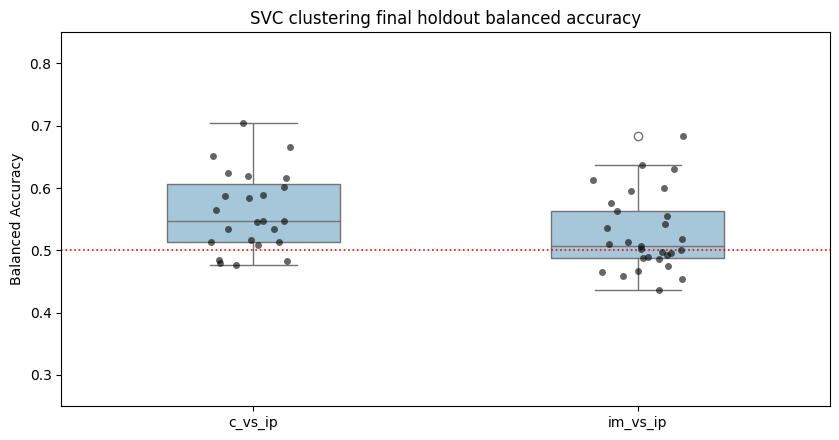

Figure saved to: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\svc_clustering\figures\svc_clustering_final_holdout_boxplot.png


In [10]:
df_dev_all = pd.DataFrame(all_dev_rows)
df_final_all = pd.DataFrame(all_final_rows)

if not df_dev_all.empty:
    summary_dev = (
        df_dev_all.groupby(["Task", "Subject"])[["Accuracy", "Balanced Accuracy", "ROC AUC"]]
        .mean()
        .reset_index()
        .groupby("Task")
        .agg(
            mean_balanced_accuracy=("Balanced Accuracy", "mean"),
            std_balanced_accuracy=("Balanced Accuracy", "std"),
            mean_auc=("ROC AUC", "mean"),
            n_subjects=("Subject", "nunique"),
        )
        .reset_index()
    )
    summary_dev_path = paths.tables_dir / "svc_clustering_development_summary.csv"
    summary_dev.to_csv(summary_dev_path, index=False)
    print("Development summary saved to:", summary_dev_path)
    print(summary_dev.to_string(index=False))

if not df_final_all.empty:
    summary_final = (
        df_final_all.groupby("Task")
        .agg(
            mean_balanced_accuracy=("Balanced Accuracy", "mean"),
            std_balanced_accuracy=("Balanced Accuracy", "std"),
            mean_auc=("ROC AUC", "mean"),
            n_subjects=("Subject", "nunique"),
            n_test_trials=("N Test", "sum"),
        )
        .reset_index()
    )
    summary_final_path = paths.tables_dir / "svc_clustering_final_holdout_summary.csv"
    summary_final.to_csv(summary_final_path, index=False)
    print("Final holdout summary saved to:", summary_final_path)
    print(summary_final.to_string(index=False))

    plt.figure(figsize=(8.5, 4.5))
    sns.boxplot(data=df_final_all, x="Task", y="Balanced Accuracy", color="#9ecae1", width=0.45)
    sns.stripplot(data=df_final_all, x="Task", y="Balanced Accuracy", color="black", alpha=0.6, jitter=0.12)
    plt.axhline(0.5, color="red", linestyle=":", linewidth=1.2)
    plt.title("SVC clustering final holdout balanced accuracy")
    plt.xlabel("")
    plt.ylabel("Balanced Accuracy")
    plt.ylim(0.25, 0.85)
    plt.tight_layout()
    fig_path = paths.figures_dir / "svc_clustering_final_holdout_boxplot.png"
    plt.savefig(fig_path, dpi=220, bbox_inches="tight")
    plt.show()
    print("Figure saved to:", fig_path)
else:
    print("No final holdout rows available.")